# 09 · El bloque MLCA y los dos encoders congelados

Primeras pruebas de la propuesta RGB-D (`proposal/PROPUESTA_RGBD_MLCA.md`).
No son ablaciones: comprueban que el bloque hace lo que la propuesta promete antes de entrenar nada, así que no
llevan predicción previa.

**Prueba 1 — el bloque solo, con datos sintéticos** (`src/mlca.py`):

1. Sin profundidad sale exactamente la red RGB (igualdad bit a bit, no «casi igual»).
2. Los huecos se excluyen de forma exacta: el resultado coincide con calcular solo sobre las celdas válidas,
   y meter basura o NaN en los huecos no cambia nada.
3. El coste crece linealmente con el número de tokens; la atención softmax, cuadráticamente.
4. El gradiente llega al bloque desde el primer paso, y no llega a los rasgos de profundidad de los huecos.

**Prueba 2 — DeFM ResNet-18 y EfficientViT-B1 congelados a 480×640:** qué tamaños de rasgos salen, cómo se
emparejan y qué hace el preprocesado oficial de DeFM con los huecos.

Uso de IA: notebook y módulo escritos con asistencia de IA (Claude, Anthropic); ver `DECISIONES.md`.

In [ ]:
import sys, time
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))
from mlca import MLCA, validez_a_rasgos, atencion_softmax_cruzada

FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
print(torch.__version__, DEV, torch.cuda.get_device_name() if DEV == "cuda" else "")

2.5.1+cu121 cuda NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Prueba 1: el bloque solo

Rasgos sintéticos del tamaño de la escala 1/8 a 480×640: 60×80 = 4 800 tokens. Color con 64 canales (la etapa
2 de EfficientViT-B1) y profundidad con 128 (P3 de DeFM), como en la §2.

In [ ]:
B, H, W = 2, 60, 80
f_rgb = torch.randn(B, 64, H, W, dtype=torch.float64)
f_prof = torch.randn(B, 128, H, W, dtype=torch.float64)
bloque = MLCA(64, 128, dim=64, cabezas=4).double()

# Huecos: manchas contiguas (como los de un sensor estéreo) más píxeles sueltos
valida = torch.ones(B, 1, H, W, dtype=torch.float64)
valida[0, :, 10:30, 20:50] = 0
valida[1, :, 40:, :25] = 0
valida[torch.rand_like(valida) < 0.05] = 0
print(f"celdas válidas: {valida.mean():.1%}")

celdas válidas: 84.0%


### 1.1 Sin profundidad sale exactamente la red RGB

Dos casos. Al inicio la salida vale cero, así que el bloque es la identidad con o sin profundidad. Lo que importa
es el segundo: con **pesos de salida cualesquiera** (como tras entrenar) y máscara toda en cero, la salida
también es exactamente el color, porque S = 0 y z = 0.

In [ ]:
print("al inicio, con profundidad completa :", torch.equal(bloque(f_rgb, f_prof, torch.ones_like(valida)), f_rgb))

entrenado = MLCA(64, 128, dim=64, cabezas=4).double()
torch.nn.init.normal_(entrenado.salida.weight, std=0.5)                  # simula un bloque ya entrenado
sin_prof = torch.zeros_like(valida)
print("pesos cualesquiera, sin profundidad :", torch.equal(entrenado(f_rgb, f_prof, sin_prof), f_rgb))
print("ídem, profundidad = NaN en todo     :",
      torch.equal(entrenado(f_rgb, torch.full_like(f_prof, float("nan")), sin_prof), f_rgb))
print("pesos cualesquiera, con profundidad : cambia en",
      f"{(entrenado(f_rgb, f_prof, valida) - f_rgb).abs().max():.3g} (máx. abs.)")

al inicio, con profundidad completa : True
pesos cualesquiera, sin profundidad : True
ídem, profundidad = NaN en todo     : True
pesos cualesquiera, con profundidad : cambia en 0.949 (máx. abs.)


### 1.2 Los huecos se excluyen de forma exacta

La referencia se escribe aparte, directamente de la fórmula y quitando las celdas inválidas antes de sumar.
También con máscara fraccionaria (la que sale de `validez_a_rasgos` cuando una celda está medida a medias).

In [ ]:
def referencia(blq, f_rgb, f_prof, m):
    # Calcula o_i sumando SOLO sobre las celdas con m > 0, cabeza por cabeza, con bucles explícitos
    b, _, h, w = f_rgb.shape
    q = F.relu(blq.q(f_rgb)).flatten(2)                 # (B, dim, N)
    k = F.relu(blq.k(f_prof)).flatten(2)
    v = blq.v(f_prof).flatten(2)
    d = q.shape[1] // blq.cabezas
    sal = torch.zeros_like(q)
    for bi in range(b):
        mj = m[bi].flatten()
        j = torch.nonzero(mj > 0).squeeze(1)            # solo las válidas
        for c in range(blq.cabezas):
            s = slice(c * d, (c + 1) * d)
            kk, vv, ww = k[bi, s][:, j], v[bi, s][:, j], mj[j]
            S = (kk * ww) @ vv.T                       # (d, d)
            z = (kk * ww).sum(1)                        # (d,)
            qq = q[bi, s]                               # (d, N)
            sal[bi, s] = (S.T @ qq) / (z @ qq + blq.eps)
    return f_rgb + blq.salida(sal.reshape(b, -1, h, w))

fraccion = valida * torch.rand_like(valida).clamp(min=0.1)     # pesos en (0, 1] donde hay medida
for nombre, m in [("binaria", valida), ("fraccionaria", fraccion)]:
    dif = (entrenado(f_rgb, f_prof, m) - referencia(entrenado, f_rgb, f_prof, m)).abs().max()
    print(f"máscara {nombre:12s}: dif. máx. con la referencia = {dif:.2e}")

basura = f_prof.clone()
huecos = (valida == 0).expand_as(basura)
basura[huecos] = 1e6 * torch.randn(int(huecos.sum()), dtype=basura.dtype)
con_nan = f_prof.clone(); con_nan[huecos] = float("nan")
limpio = entrenado(f_rgb, f_prof, valida)
print("basura de 1e6 en los huecos, idéntico:", torch.equal(entrenado(f_rgb, basura, valida), limpio))
print("NaN en los huecos, idéntico          :", torch.equal(entrenado(f_rgb, con_nan, valida), limpio))

máscara binaria     : dif. máx. con la referencia = 1.01e-07
máscara fraccionaria: dif. máx. con la referencia = 1.48e-07


basura de 1e6 en los huecos, idéntico: True
NaN en los huecos, idéntico          : True


### 1.3 Coste lineal frente a cuadrático

Tiempo en la GPU de este equipo (no en la Jetson) del bloque MLCA y de una atención cruzada softmax de
referencia (`scaled_dot_product_attention`, con los núcleos eficientes de PyTorch), en FP32, con 64 canales y 4
cabezas, de 1 200 a 76 800 tokens (de 30×40 a 240×320). Lo que interesa es la **pendiente** en escala log-log:
1 es lineal y 2 cuadrático. Son tiempos de PyTorch con sincronización, no latencias para reportar.

 30× 40 =   1200 tokens   MLCA   4.778 ms   softmax    1.542 ms


 60× 80 =   4800 tokens   MLCA   2.279 ms   softmax    8.696 ms


 90×120 =  10800 tokens   MLCA   1.795 ms   softmax   30.514 ms


120×160 =  19200 tokens   MLCA   2.234 ms   softmax   91.338 ms


180×240 =  43200 tokens   MLCA   1.621 ms   softmax  459.848 ms


240×320 =  76800 tokens   MLCA   3.894 ms   softmax 1451.808 ms

pendiente log-log (desde 19 200 tokens):  MLCA 0.35   softmax 2.00


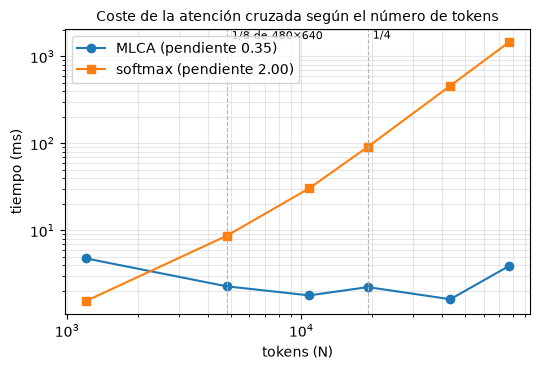

In [ ]:
def medir(fn, rep=30):
    for _ in range(10):                                  # calentamiento: la GPU sube de reloj
        fn()
    if DEV == "cuda":
        torch.cuda.synchronize()
    ts = []
    for _ in range(rep):
        t0 = time.perf_counter(); fn()
        if DEV == "cuda":
            torch.cuda.synchronize()
        ts.append(time.perf_counter() - t0)
    return 1e3 * float(np.median(ts))

blq = MLCA(64, 64, dim=64, cabezas=4).to(DEV).eval()
tamanos = [(30, 40), (60, 80), (90, 120), (120, 160), (180, 240), (240, 320)]
N, t_mlca, t_soft = [], [], []
with torch.no_grad():
    for h, w in tamanos:
        a = torch.randn(1, 64, h, w, device=DEV); p = torch.randn(1, 64, h, w, device=DEV)
        m = torch.ones(1, 1, h, w, device=DEV)
        N.append(h * w)
        t_mlca.append(medir(lambda: blq(a, p, m)))
        t_soft.append(medir(lambda: atencion_softmax_cruzada(a, p)))
        print(f"{h:3d}×{w:3d} = {h*w:6d} tokens   MLCA {t_mlca[-1]:7.3f} ms   softmax {t_soft[-1]:8.3f} ms")

# Pendiente con los tres tamaños grandes: por debajo de ~20 000 tokens el MLCA tarda casi lo mismo
# (domina el coste fijo de lanzar los núcleos), y esa parte plana rebajaría la pendiente
g = slice(3, None)
p_mlca = np.polyfit(np.log(N[g]), np.log(t_mlca[g]), 1)[0]
p_soft = np.polyfit(np.log(N[g]), np.log(t_soft[g]), 1)[0]
print(f"\npendiente log-log (desde 19 200 tokens):  MLCA {p_mlca:.2f}   softmax {p_soft:.2f}")

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.loglog(N, t_mlca, "o-", label=f"MLCA (pendiente {p_mlca:.2f})")
ax.loglog(N, t_soft, "s-", label=f"softmax (pendiente {p_soft:.2f})")
for n, txt in [(4800, "1/8 de 480×640"), (19200, "1/4")]:
    ax.axvline(n, color="0.7", lw=0.8, ls="--"); ax.text(n * 1.05, 2e3, txt, fontsize=8, va="top")
ax.set_xlabel("tokens (N)"); ax.set_ylabel("tiempo (ms)"); ax.legend(); ax.grid(alpha=0.3, which="both")
ax.set_title("Coste de la atención cruzada según el número de tokens", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "09_1_coste.png", dpi=150); plt.show()

### 1.4 El gradiente

Al inicio la salida vale cero: el gradiente llega a la proyección de salida pero todavía no a q, k y v (pasan
por una matriz nula). Tras un paso de optimización ya llega a todo. Y el gradiente respecto de los rasgos de
profundidad de los huecos es cero exacto: la red no aprende nada de lo que el sensor no midió.

In [ ]:
nuevo = MLCA(64, 128, dim=64, cabezas=4).double()
fr = f_rgb.clone().requires_grad_(); fp = f_prof.clone().requires_grad_()
objetivo = torch.randn_like(f_rgb)
perdida = lambda: ((nuevo(fr, fp, valida) - objetivo) ** 2).mean()

perdida().backward()
norma = lambda p: 0.0 if p.grad is None else p.grad.norm().item()
print("paso 0:", {n: f"{norma(p):.2e}" for n, p in nuevo.named_parameters() if n.endswith("weight")})

opt = torch.optim.SGD(nuevo.parameters(), lr=0.1)
opt.step(); opt.zero_grad(); fr.grad = None; fp.grad = None
perdida().backward()
print("paso 1:", {n: f"{norma(p):.2e}" for n, p in nuevo.named_parameters() if n.endswith("weight")})
g_huecos = fp.grad[(valida == 0).expand_as(fp)]
g_validas = fp.grad[(valida > 0).expand_as(fp)]
print(f"gradiente en rasgos de profundidad:  huecos máx. {g_huecos.abs().max():.1e}  ·  "
      f"válidas media {g_validas.abs().mean():.1e}")

paso 0: {'q.weight': '0.00e+00', 'k.weight': '0.00e+00', 'v.weight': '0.00e+00', 'salida.weight': '5.12e-03'}


paso 1: {'q.weight': '5.54e-07', 'k.weight': '1.77e-06', 'v.weight': '1.83e-06', 'salida.weight': '5.12e-03'}
gradiente en rasgos de profundidad:  huecos máx. 0.0e+00  ·  válidas media 1.8e-11


### 1.5 Precisión reducida

Las sumas S y z se hacen en FP32 aunque la red corra en FP16 o BF16 (`autocast`). Aquí se compara la salida
del bloque bajo `autocast` FP16 con la de FP32, con rasgos grandes (×30) para forzar el caso malo.

In [ ]:
if DEV == "cuda":
    blq16 = MLCA(64, 128, dim=64, cabezas=4).to(DEV)
    torch.nn.init.normal_(blq16.salida.weight, std=0.05)
    a = 30 * torch.randn(1, 64, 120, 160, device=DEV); p = 30 * torch.randn(1, 128, 120, 160, device=DEV)
    m = torch.ones(1, 1, 120, 160, device=DEV)
    with torch.no_grad():
        ref = blq16(a, p, m)
        with torch.autocast("cuda", dtype=torch.float16):
            o16 = blq16(a, p, m)
        with torch.autocast("cuda", dtype=torch.float16):
            k16 = F.relu(blq16.k(p))
        print("salida finita con autocast FP16:", bool(torch.isfinite(o16).all()),
              f"· dif. relativa con FP32 {((o16.float() - ref).norm() / ref.norm()):.1e}")
        print("la suma z hecha en FP16 en cambio:", k16.flatten(2).sum(-1).max().item(), "(inf = desborde)")

salida finita con autocast FP16: True · dif. relativa con FP32 1.7e-05
la suma z hecha en FP16 en cambio: inf (inf = desborde)


## 2. Prueba 2: los encoders congelados a 480×640

DeFM ResNet-18 se carga por `torch.hub` desde el repositorio oficial (`leggedrobotics/defm`, Apache 2.0) y su
preprocesado es el del código oficial (`defm.utils.utils.preprocess_depth_image`). EfficientViT-B1 con
`efficientvit_seg.cargar_efficientvit` (pesos ADE20K). Ambos congelados.

La profundidad es sintética: un suelo plano visto por la D455 a 1 m de altura y 34° hacia abajo, con huecos
del 13 % (lo que falta en `rawDepths` de NYUv2 dentro del recorte de Eigen).

In [ ]:
import efficientvit_seg as S
defm = torch.hub.load("leggedrobotics/defm:main", "defm_resnet18", pretrained=True, trust_repo=True,
                      verbose=False).to(DEV).eval().requires_grad_(False)
from defm.utils.utils import preprocess_depth_image, convert_to_3channel_metric
evit = S.cargar_efficientvit("b1", "ade20k").to(DEV).eval().requires_grad_(False)
mp = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
print(f"DeFM ResNet-18 + BiFPN: {mp(defm):.2f} M  (ResNet {mp(defm.backbone):.2f} M, BiFPN {mp(defm.fpn):.2f} M)")
print(f"EfficientViT-B1: {mp(evit):.2f} M  (backbone {mp(evit.backbone):.2f} M)")

Backbone resnet18 feature channels: [128, 256, 512]


Loaded DeFM weights from <ruta local> with result: <All keys matched successfully>


DeFM ResNet-18 + BiFPN: 11.74 M  (ResNet 11.18 M, BiFPN 0.56 M)
EfficientViT-B1: 4.79 M  (backbone 4.64 M)


In [ ]:
# Profundidad de un suelo plano: cámara a 1 m, 34° hacia abajo, intrínsecos aproximados de la D455 a 640×480
Hh, Ww, fy, cy = 480, 640, 385.0, 240.0
ang = np.deg2rad(34) + np.arctan((np.arange(Hh) - cy) / fy)          # ángulo bajo la horizontal por fila
z_fila = np.where(ang > 0.02, 1.0 / np.sin(np.clip(ang, 0.02, None)) * np.cos(ang - np.deg2rad(34)), 20.0)
prof = np.repeat(np.clip(z_fila, 0, 20)[:, None], Ww, 1).astype(np.float32)
prof += 0.01 * np.random.default_rng(0).standard_normal(prof.shape).astype(np.float32)

rng = np.random.default_rng(1)
hueco = np.zeros_like(prof, bool)
while hueco.mean() < 0.13:                                           # manchas como las de un estéreo
    y, x = rng.integers(0, Hh), rng.integers(0, Ww); r = rng.integers(5, 30)
    hueco[max(0, y - r):y + r, max(0, x - r):x + r] = True
prof_huecos = np.where(hueco, 0.0, prof).astype(np.float32)          # el sensor marca los huecos con 0
print(f"huecos: {hueco.mean():.1%} · profundidad válida de {prof[~hueco].min():.2f} a {prof[~hueco].max():.2f} m")

x_d = preprocess_depth_image(prof_huecos, target_size=(Hh, Ww))
print("dtype del preprocesado oficial:", x_d.dtype, "-> se pasa a float32")
x_d = x_d.float().to(DEV)

huecos: 13.1% · profundidad válida de 0.90 a 20.03 m
dtype del preprocesado oficial: torch.float64 -> se pasa a float32


### 2.1 Lo que hace el preprocesado oficial con los huecos

El tercer canal de DeFM normaliza cada imagen con su mínimo y su máximo. El mínimo se toma **con los ceros de
los huecos incluidos**: basta un hueco para que cambie la codificación de todos los píxeles válidos. Además,
`convert_to_3channel_metric` usa 9 m y no 10 m para el segundo canal (lo dice su propio comentario).

canal 1: cambio en los píxeles VÁLIDOS al haber huecos = máx. 0.000, media 0.000
canal 2: cambio en los píxeles VÁLIDOS al haber huecos = máx. 0.000, media 0.000
canal 3: cambio en los píxeles VÁLIDOS al haber huecos = máx. 0.210, media 0.161


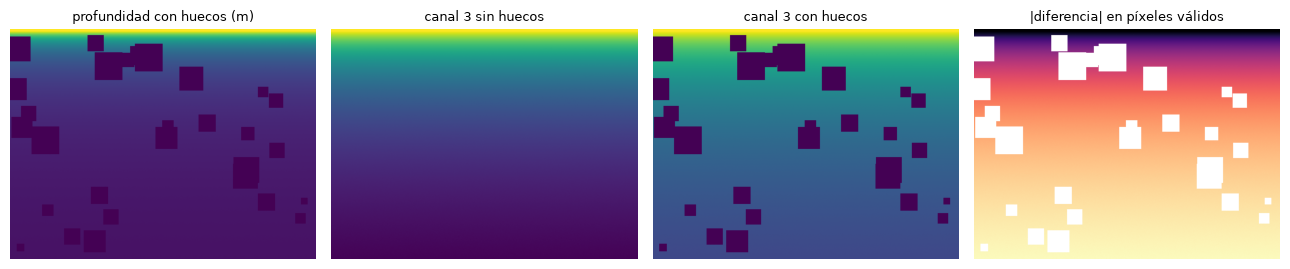

In [ ]:
sin = convert_to_3channel_metric(prof)
con = convert_to_3channel_metric(prof_huecos)
for c in range(3):
    d = np.abs(sin[..., c] - con[..., c])[~hueco]
    print(f"canal {c + 1}: cambio en los píxeles VÁLIDOS al haber huecos = máx. {d.max():.3f}, media {d.mean():.3f}")

fig, ax = plt.subplots(1, 4, figsize=(13, 2.8))
ax[0].imshow(prof_huecos, cmap="viridis"); ax[0].set_title("profundidad con huecos (m)", fontsize=9)
ax[1].imshow(sin[..., 2], vmin=0, vmax=1); ax[1].set_title("canal 3 sin huecos", fontsize=9)
ax[2].imshow(con[..., 2], vmin=0, vmax=1); ax[2].set_title("canal 3 con huecos", fontsize=9)
ax[3].imshow(np.where(hueco, np.nan, np.abs(sin[..., 2] - con[..., 2])), cmap="magma")
ax[3].set_title("|diferencia| en píxeles válidos", fontsize=9)
for a in ax: a.axis("off")
fig.tight_layout(); fig.savefig(FIGS / "09_2_canal_minmax.png", dpi=130); plt.show()

### 2.2 Tamaños de los rasgos y emparejamiento

In [ ]:
x_rgb = torch.randn(1, 3, Hh, Ww, device=DEV)                       # el contenido no importa para las formas
with torch.no_grad():
    fd = defm(x_d)["dense_bifpn"]
    fc = evit.backbone(x_rgb)
print("DeFM :", {k: tuple(v.shape[1:]) for k, v in fd.items()})
print("EViT :", {k: tuple(v.shape[1:]) for k, v in fc.items() if k.startswith("stage")})
print("la cabeza de EfficientViT lee:", evit.head.input_keys)

pares = [("stage2", "P3"), ("stage3", "P4"), ("stage4", "P5")]
valida_img = torch.from_numpy(~hueco)[None, None].to(DEV)
print(f"\n{'escala':>6} {'color':>14} {'profundidad':>14} {'tokens':>7} {'celdas sin medida':>18}")
for c, d in pares:
    a, b = fc[c], fd[d]
    assert a.shape[-2:] == b.shape[-2:]
    m = validez_a_rasgos(valida_img, a.shape[-2:])
    print(f"1/{Hh // a.shape[-2]:<4} {c + ' ' + str(a.shape[1]):>14} {d + ' ' + str(b.shape[1]):>14} "
          f"{a.shape[-2] * a.shape[-1]:7d} {(m == 0).float().mean().item():17.1%}")

DeFM : {'P3': (128, 60, 80), 'P4': (128, 30, 40), 'P5': (128, 15, 20)}
EViT : {'stage0': (16, 240, 320), 'stage1': (32, 120, 160), 'stage2': (64, 60, 80), 'stage3': (128, 30, 40), 'stage4': (256, 15, 20), 'stage_final': (256, 15, 20)}
la cabeza de EfficientViT lee: ['stage4', 'stage3', 'stage2']

escala          color    profundidad  tokens  celdas sin medida
1/8         stage2 64         P3 128    4800              9.2%
1/16       stage3 128         P4 128    1200              5.6%
1/32       stage4 256         P5 128     300              1.3%


### 2.3 Los tres bloques sobre los rasgos reales

Un MLCA por escala, entre la etapa de EfficientViT y la escala de DeFM con la misma resolución. Se comprueba de
nuevo la garantía del §1.1, ahora con los rasgos de los encoders, y se cuentan los parámetros entrenables
(los encoders siguen congelados).

In [ ]:
bloques = torch.nn.ModuleDict({c: MLCA(fc[c].shape[1], fd[d].shape[1], cabezas=4) for c, d in pares}).to(DEV)
for blq in bloques.values():
    torch.nn.init.normal_(blq.salida.weight, std=0.05)              # como si ya estuviera entrenado
with torch.no_grad():
    for c, d in pares:
        m = validez_a_rasgos(valida_img, fc[c].shape[-2:])
        sin_prof = bloques[c](fc[c], fd[d], torch.zeros_like(m))
        con_prof = bloques[c](fc[c], fd[d], m)
        print(f"{c}: sin profundidad == color: {torch.equal(sin_prof, fc[c])}   "
              f"con profundidad cambia {((con_prof - fc[c]).norm() / fc[c].norm()):.2%}")
entren = sum(p.numel() for p in bloques.parameters())
print(f"\nparámetros entrenables de los tres bloques: {entren / 1e3:.1f} k "
      f"(encoders congelados: {mp(defm) + mp(evit.backbone):.2f} M)")

stage2: sin profundidad == color: True   con profundidad cambia 34.89%
stage3: sin profundidad == color: True   con profundidad cambia 33.24%
stage4: sin profundidad == color: True   con profundidad cambia 92.71%

parámetros entrenables de los tres bloques: 288.1 k (encoders congelados: 16.38 M)


## 3. Resumen

Las cifras de arriba son la fuente. Lo que queda para las pruebas siguientes de la propuesta: profundidad real
(NYUv2 `rawDepths`), entrenamiento con una predicción previa del equipo, y la medición en la Jetson AGX Orin
con TensorRT.

> ✍️ **Lectura del equipo:** (pendiente)